# Q6 Destatis: Population Germany (12411-0001) – Explore

**Goal of Explore:** understand what's in the raw data and what to do during cleaning. We change nothing in `data/raw/`.

Source: © Statistisches Bundesamt (Destatis), 2026, License dl-de/by-2-0.

## Look at data as text
Before Python reads the data, we must understand how it's put together. That's how we know what options we need.

In [1]:
RAW = "../../data/raw/destatis/12411-0001_de.csv"  # path relative to this notebook (notebooks/q6_destatis_population/)

with open(RAW, encoding="utf-8-sig") as f:         # utf-8-sig=UTF-8, removes invisible BOM character at the start, if there is one
    lines = f.read().splitlines()                  # list with one entry per line of the file

print("Number of lines:", len(lines))
print("--- Beginning ---")
for l in lines[:10]: print(repr(l))                # first 10 lines; repr() shows the line with quotes, so hidden characters and empty lines are visible
print("--- End ---")
for l in lines[-10:]: print(repr(l))               # last 10 lines (a negative number counts from the end)

Number of lines: 89
--- Beginning ---
'Tabelle: 12411-0001'
'Bevölkerung: Deutschland, Stichtag;'
'Fortschreibung des Bevölkerungsstandes;;'
'Deutschland;;'
';Bevölkerungsstand;Bevölkerungsstand'
';Anzahl;Anzahl'
'31.12.1950;50958125;e'
'31.12.1951;51434777;e'
'31.12.1952;51863761;e'
'31.12.1953;52453806;e'
--- End ---
'31.12.2023;83456045;e'
'31.12.2024;83577140;e'
'31.12.2025;83467117;e'
'__________'
'"Bis 1989: Früheres Bundesgebiet'
''
'Ab 2011: Ergebnisse auf Grundlage des Zensus 2011.'
'Ab 2022: Ergebnisse auf Grundlage des Zensus 2022."'
'© Statistisches Bundesamt (Destatis), 2026'
'Stand: 22.10.2026 / 16:44:14'


## Read with pandas
`skiprows` skips the beginning that doesn't contain data, `nrows` reads only the data. `header=None`, since the data doesn't have a clean header. Row numbers are taken from our first step.

In [2]:
import pandas as pd

# data lines start with a date, meaning two digits
# header, title lines and footnotes start with letters or other non-digit characters, so they are not matched
first_data = next(i for i, l in enumerate(lines) if l[:2].isdigit())   # number of the first line that starts with a digit (= first date)
last_data = max(i for i, l in enumerate(lines) if l[:2].isdigit())     # number of the last line that starts with a digit
print("first data row:", first_data, "| last data row:", last_data)

# Now pandas reads only the data lines:
# sep=";" -> columns are separated by semicolons
# header=None -> no usable header row, no line is used as column name
# skiprows=first_data -> skips everything before the first data line (title, description, unit)
# nrows=... -> reads as many rows as there are data lines (footnotes stay out)
# names=[...] -> gives the three columns specific names
df = pd.read_csv(RAW, sep=";", encoding="utf-8-sig", header=None,
                 skiprows=first_data, nrows=last_data - first_data + 1,
                 names=["date_raw", "population_raw", "value_status"])
df.head()                                                              # shows the first 5 rows 

first data row: 6 | last data row: 81


,date_raw,population_raw,value_status
0,31.12.1950,50958125,e
1,31.12.1951,51434777,e
2,31.12.1952,51863761,e
3,31.12.1953,52453806,e
4,31.12.1954,52943295,e


**Notes:**
- First 6 lines are header, description, overview with reference date and unit (number), no data.
- Last 7 lines are footnotes and further information on the source, no data.
- Footnote 'Bis 1989: Früheres Bundesgebiet': Until 1989, the data only covers the former federal territory (West Germany). After German reunification in 1990, further states were added.
- Data is encoded in UTF-8. `utf-8-sig` was chosen to be able to read the data even if it starts with an invisible character (BOM).
- Separator is a semicolon (';').
- Source: © Statistisches Bundesamt (Destatis), 2026 - © Federal Statistical Office of Germany (Destatis), 2026
- File date (Stand): '22.10.2026 / 16:44:14'
- `e` = 'endgültiger Wert' - final value

## How many rows? What datatypes?

In [3]:
print(df.shape)  # number of rows, number of columns
df.info()        # column names, number of non-empty values and datatype of each column

(76, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   date_raw        76 non-null     object
 1   population_raw  76 non-null     int64 
 2   value_status    76 non-null     object
dtypes: int64(1), object(2)
memory usage: 1.9+ KB


**Notes:**
- If we need data from 1950 to 2025, with each year having exactly one entry, we would need 76 rows, which we do have.
- The population count (`population_raw`) is stored as an integer (`int64`).
- `date_raw` is text (datatype `object`) and needs to be converted to a year.

## Missing values, placeholders

In [4]:
print(df.isna().sum())                   # isna() marks empty cells, sum() counts them per column
print(df["value_status"].value_counts()) # how often each value appears in this column
# turns the numbers into text, then looks for any character that is not a digit (regex [^0-9])
# sum() counts the rows where that is true
# this reveals placeholders like '.' or '-' that Destatis sometimes uses instead of numbers
print(df["population_raw"].astype(str).str.contains(r"[^0-9]").sum(), "non-digit values")

date_raw          0
population_raw    0
value_status      0
dtype: int64
value_status
e    76
Name: count, dtype: int64
0 non-digit values


**Notes:**
- We have no missing values.
- `e` = 'endgültiger Wert' - final value
- `value_status` is in all 76 rows classified as `e`.
- `population_raw` has 0 non-digit values. All the values are proper numbers.

## Missing years?

In [5]:
# "31.12.1950" is only text, so it must be converted into a real date (day.month.year) and only the year is kept.
df["year"] = pd.to_datetime(df["date_raw"], format="%d.%m.%Y").dt.year
print("Years:", df["year"].min(), "to", df["year"].max())
print("Years unique:", df["year"].is_unique)                             # True = no year appears twice
# all years from the first to the last, minus the years we actually have -> what is left is missing
# (+ 1 because range() stops before its end value)
missing = sorted(set(range(df["year"].min(), df["year"].max() + 1)) - set(df["year"]))
print("Missing years:", missing)                                         # [] = empty list = no year is missing

Years: 1950 to 2025
Years unique: True
Missing years: []


**Notes:**
- For each year we have exactly one entry.
- We have no missing years, the timeline is complete.

## Range of values

In [6]:
sub = df[df["year"].between(2001, 2025)]    # only the rows of our project period (both years included)
sub["population_raw"].describe()            # count, mean, standard deviation, min, quartiles (25/50/75 %), max

count    2.500000e+01
mean     8.236159e+07
std      9.020971e+05
min      8.032790e+07
25%      8.200236e+07
50%      8.250085e+07
75%      8.311850e+07
max      8.357714e+07
Name: population_raw, dtype: float64

**Notes:**
- Between 2001 and 2025 the population ranges from about 80.3 to about 83.6 million, which is plausible for Germany.

## Line graph for visualization
A line graph can show jumps that are easily overlooked in numbers.

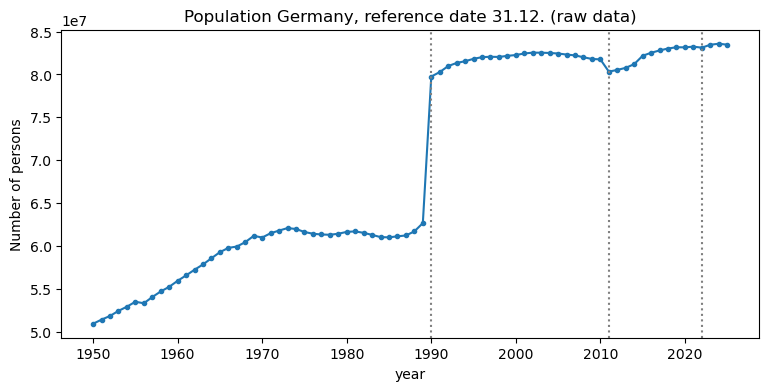

In [7]:
import matplotlib.pyplot as plt

# set_index("year") puts the year on the x-axis, ["population_raw"] picks the values for the y-axis,
# .plot() draws the line (figsize = size, marker = a dot for every year)
ax = df.set_index("year")["population_raw"].plot(figsize=(9, 4), marker="o", markersize=3)
ax.set_title("Population Germany, reference date 31.12. (raw data)")
ax.set_ylabel("Number of persons")
for y in (1990, 2011, 2022):                      # 1990 = reunification (footnote: "until 1989"), 2011 and 2022 = censuses
    ax.axvline(y, color="grey", linestyle=":")    # dotted vertical line at that year
plt.show()                                        # show the plot

**Notes:**
- Large jump in 1990, matching the footnote mentioning the new federal territory (German reunification). This lies outside 2001-2025 and is therefore irrelevant for the group project.
- Clear drop in 2011, small step in 2022, matching the footnote mentioning the new census taken in both 2011 and 2022, correcting the previous numbers.

In [8]:
# yearly change: where is it the biggest?
# diff() = value minus the value of the previous year (the first year, 1950, has no predecessor and gets NaN = "not a number")
# .loc[2001:2025] keeps the years 2001 to 2025 (.loc uses the labels, here the years, and includes both ends)
change = df.set_index("year")["population_raw"].diff().loc[2001:2025]   # only years 2001-2025 are considered for the project
print(change.sort_values().head(3))                                     # sorted from smallest to largest: the first 3 are the biggest drops
print(change.sort_values().tail(3))                                     # the last 3 are the biggest increases (the largest value is at the bottom)

year
2011   -1423702.0
2008    -215481.0
2009    -200099.0
Name: population_raw, dtype: float64
year
2016    345969.0
2014    430074.0
2015    978147.0
Name: population_raw, dtype: float64


**Notes:**
- Clear drop in 2011 matching the footnote mentioning the new census taken in 2011. It's a statistical correction, not actual population decline. Comparisons across 2011 (before vs. after) should be done with care. 2011: -1,423,702 is the biggest drop, however 2008: -215,481 and 2009: -200,099 are much smaller.
- Biggest jump in 2015 with +978,147. The footnotes do not explain why. 2014: +430,074 and 2016: +345,969 are the second and third biggest jumps in our selected timeline.

## Overview
- Data has:
    - 89 lines in total, of which 76 are relevant data
    - Years noted are 1950 to 2025
    - no missing values
- Large jump in year 1990, a clear drop in 2011 (statistical correction, not actual population decline), small step in 2022
- Conclusion: We keep years 2001-2025 (our focus in the group project) and work with this period as a baseline.
- Cleaning process must include:
    - turning the dates into years (already done here)
    - filter data from 2001-2025
    - rename columns (`year`, `population`)
    - drop `value_status`, column carries no further relevant information since all values are final (`e`)
    - document the 2011 break (census), no correction of our own